# ARIMA 

In [1]:
import pandas as pd

import numpy as np

import matplotlib.pyplot as plt

from statsmodels.tsa.arima.model import ARIMA

from statsmodels.tsa.stattools import adfuller

from statsmodels.graphics.tsaplots import plot_acf,plot_pacf

from sklearn.metrics import mean_absolute_error, mean_squared_error

import warnings
warnings.filterwarnings("ignore")

In [2]:
df = pd.read_csv('sales.csv')
df.head()

,Date,Sales
0,2024-01-01,102
1,2024-01-02,103
2,2024-01-03,110
3,2024-01-04,117
4,2024-01-05,111


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 365 entries, 0 to 364
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   Date    365 non-null    str  
 1   Sales   365 non-null    int64
dtypes: int64(1), str(1)
memory usage: 9.4 KB


In [4]:
df.isnull().sum()

Date     0
Sales    0
dtype: int64

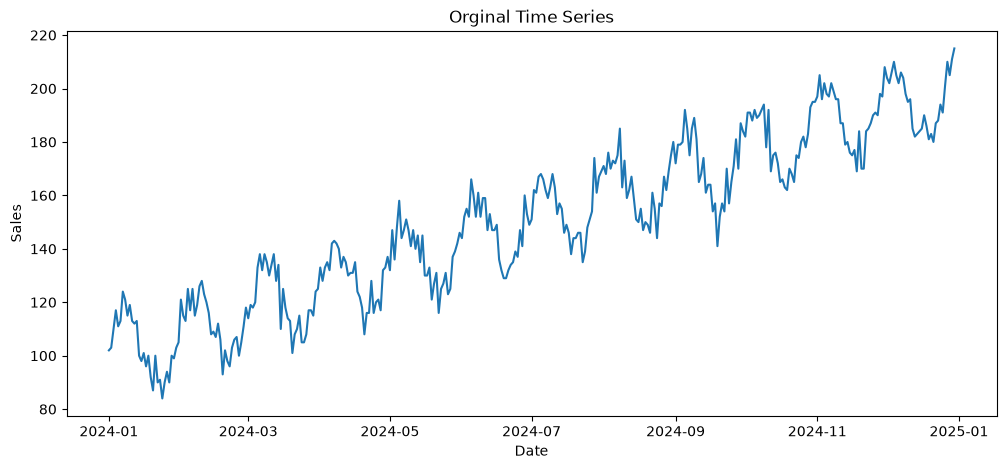

In [5]:
df['Date']=pd.to_datetime(df['Date'])
df.set_index('Date',inplace=True)
plt.figure(figsize=(12,5))
plt.plot(df['Sales'])
plt.title('Orginal Time Series')
plt.xlabel('Date')
plt.ylabel('Sales')
plt.show()

In [6]:
result=adfuller(df['Sales'])

print('ADF Statistic:',result[0])
print('p-value:',result[1])

if result[1] < 0.05:
    print('Data is Stationary')
else:
    print('Data is NOT Stationary')

ADF Statistic: -0.28438041379886614
p-value: 0.9276875854390807
Data is NOT Stationary


In [7]:
df['Sales_diff']=df['Sales'].diff()
df

,Sales,Sales_diff
Date,,
2024-01-01,102,NaN
2024-01-02,103,1.0
2024-01-03,110,7.0
2024-01-04,117,7.0
2024-01-05,111,-6.0
...,...,...
2024-12-26,201,10.0
2024-12-27,210,9.0
2024-12-28,205,-5.0


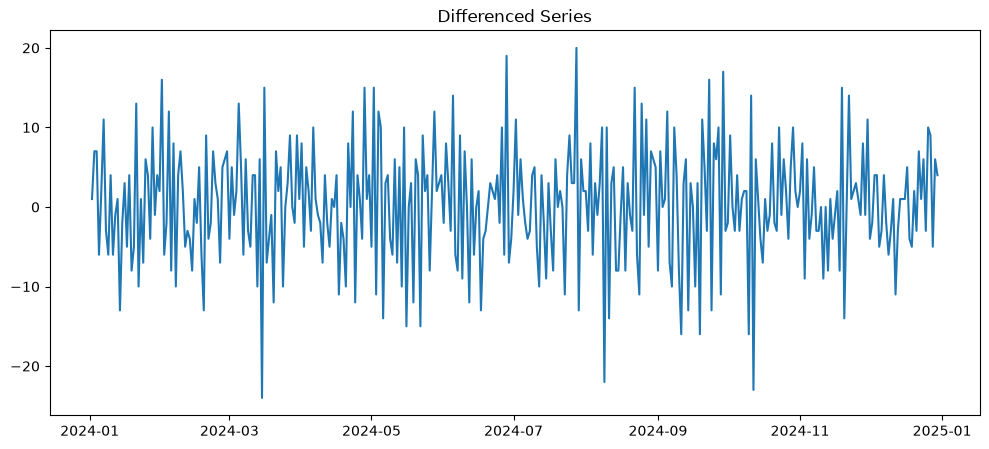

In [8]:
df=df.dropna()

plt.figure(figsize=(12,5))
plt.plot(df['Sales_diff'])
plt.title('Differenced Series')
plt.show()

In [9]:
print(adfuller(df['Sales_diff'])[1])

2.0460265483476854e-20


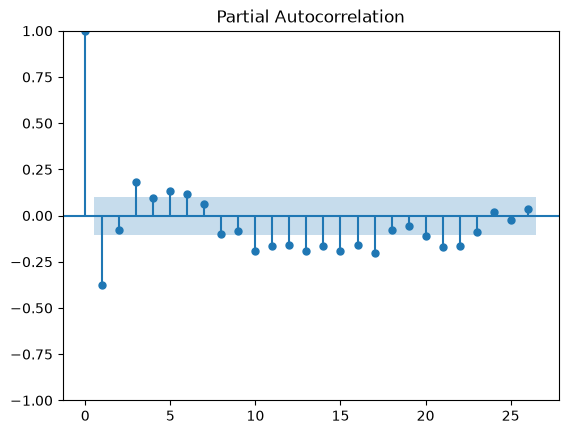

In [11]:
plot_pacf(df['Sales_diff'])
plt.show()

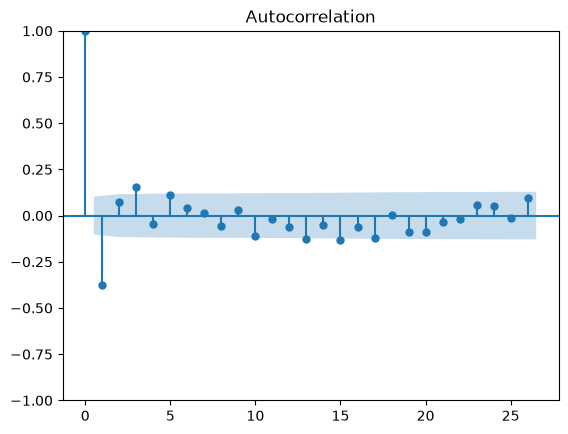

In [13]:
plot_acf(df['Sales_diff'])
plt.show()

In [14]:
train_size=int(len(df)*0.8)
print(train_size)
train=df['Sales'][:train_size]
test=df['Sales'][train_size:]

291


In [15]:
model=ARIMA(train,order=(1,1,1))

model_fit=model.fit()

print(model_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                  Sales   No. Observations:                  291
Model:                 ARIMA(1, 1, 1)   Log Likelihood                -975.535
Date:                Wed, 21 Oct 2026   AIC                           1957.070
Time:                        09:57:10   BIC                           1968.080
Sample:                    01-02-2024   HQIC                          1961.481
                         - 10-18-2024                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.2930      0.144     -2.038      0.042      -0.575      -0.011
ma.L1         -0.1210      0.157     -0.772      0.440      -0.428       0.186
sigma2        48.8788      4.003     12.212      0.0

In [16]:
forecast=model_fit.forecast(steps=len(test))

comparison=pd.DataFrame({
    'Actual':test,
    'Forecast':forecast
})
print(comparison)

            Actual    Forecast
2024-10-19     162  164.237206
2024-10-20     170  163.874696
2024-10-21     168  163.980914
2024-10-22     165  163.949791
2024-10-23     175  163.958910
...            ...         ...
2024-12-26     201  163.956844
2024-12-27     210  163.956844
2024-12-28     205  163.956844
2024-12-29     211  163.956844
2024-12-30     215  163.956844

[73 rows x 2 columns]


In [20]:
mae=mean_absolute_error(test,forecast)
mse=mean_squared_error(test,forecast)
rmse=np.sqrt(mse)

print('MAE :',mae)
print('MSE :',mse)
print('RMSE:',rmse)

MAE : 25.978191406947783
MSE : 821.1251784138464
RMSE: 28.65528185891471


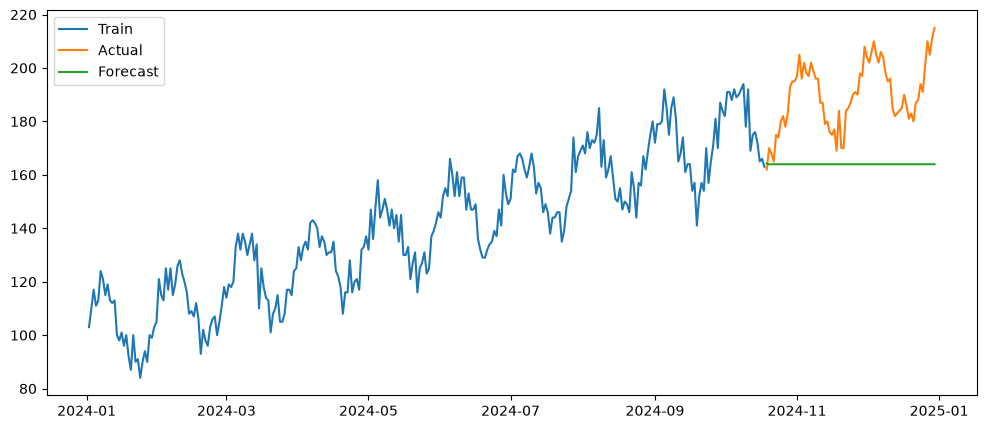

In [21]:
plt.figure(figsize=(12,5))
plt.plot(train,label='Train')
plt.plot(test,label='Actual')
plt.plot(forecast,label='Forecast')
plt.legend()
plt.show()

In [22]:
future=model_fit.forecast(steps=30)

print(future)

future.to_csv('future_prediction.csv')
print('Future predictions saved')

2024-10-19    164.237206
2024-10-20    163.874696
2024-10-21    163.980914
2024-10-22    163.949791
2024-10-23    163.958910
2024-10-24    163.956238
2024-10-25    163.957021
2024-10-26    163.956792
2024-10-27    163.956859
2024-10-28    163.956840
2024-10-29    163.956845
2024-10-30    163.956844
2024-10-31    163.956844
2024-11-01    163.956844
2024-11-02    163.956844
2024-11-03    163.956844
2024-11-04    163.956844
2024-11-05    163.956844
2024-11-06    163.956844
2024-11-07    163.956844
2024-11-08    163.956844
2024-11-09    163.956844
2024-11-10    163.956844
2024-11-11    163.956844
2024-11-12    163.956844
2024-11-13    163.956844
2024-11-14    163.956844
2024-11-15    163.956844
2024-11-16    163.956844
2024-11-17    163.956844
Freq: D, Name: predicted_mean, dtype: float64
Future predictions saved
